# 01 雪粒半径与光谱反射率

这份 Notebook 回答两个问题：雪粒半径增大时，哪些波段变化最明显；太阳天顶角和冰光学常数怎样改变结果。

本案例读取由公开 SNICAR-ADv3 和 WW80 参考实现计算的**冻结正演缓存**。运行本页会重画光谱并重新整理反照率统计，完整正演的 MATLAB 入口见仓库说明。

| 输入 | 含义 |
|---|---|
| 半径 | 30–1500 μm，间隔 10 μm，共 148 个值 |
| 波长 | 0.205–4.995 μm，共 480 个值 |
| 太阳天顶角 | 缓存包含 0°、60°、22°；本页主图比较 0°/60° |
| 雪层 | 纯净球形雪，100 m 数值厚雪层，200 kg/m³ |
| 冰光学选项 | Warren 1984 与 Warren–Brandt 2008 |

60°是课程模拟条件。实景分支采用的太阳角设定在第三份 Notebook 中另行说明。

In [1]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from snowmix import teaching as t

has_cjk_font = t.configure_plots()
print("绘图标签：" + ("中文" if has_cjk_font else "English（当前环境未安装中文字体）"))

绘图标签：中文


## 1 读取与检查数据

`snicar_albedo` 和 `ww_albedo` 的轴依次为**半径、波长、太阳天顶角、冰光学选项**。这些光谱是方向—半球反照率，值为无量纲。

In [2]:
forward = t.load_forward()
assert forward["snicar_albedo"].shape == (148, 480, 3, 2)
assert np.array_equal(forward["radii_um"], np.arange(30, 1501, 10))
assert np.isfinite(forward["snicar_albedo"]).all()
assert forward["snicar_albedo"].min() >= -1e-8
assert forward["snicar_albedo"].max() <= 1 + 1e-8
print("光谱数组：148 半径 × 480 波长 × 3 角度 × 2 光学选项")
print("反照率范围：", np.round([forward["snicar_albedo"].min(), forward["snicar_albedo"].max()], 6))

光谱数组：148 半径 × 480 波长 × 3 角度 × 2 光学选项
反照率范围： [4.5300e-04 9.9921e-01]


## 2 比较四种代表半径

每个面板使用相同坐标和颜色。先观察可见光，再观察 1 μm 附近及短波红外：粒径变化对各波段的影响不同。50、200、500、1000 μm 是代表半径；新雪和老雪的实际粒径还受雪况影响。

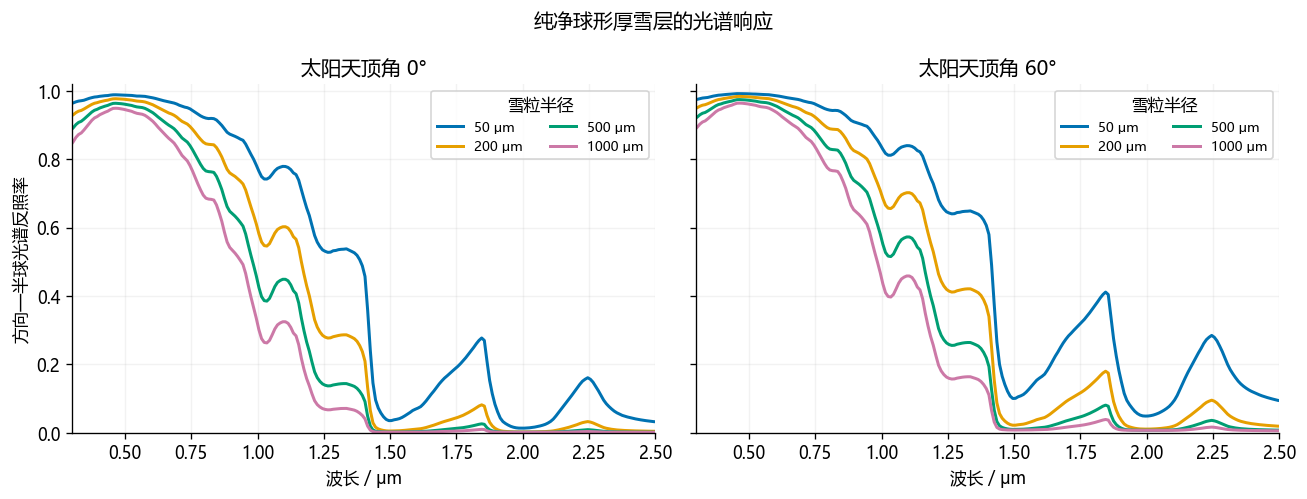

In [3]:
figure = t.plot_optical_spectra(forward)
display(figure)
plt.close(figure)

## 3 从光谱到太阳谱加权反照率

太阳谱加权反照率为
$$
\alpha=\frac{\sum_c F_{\mathrm{sun},c}R_c}{\sum_c F_{\mathrm{sun},c}},
$$
其中 $F_{\mathrm{sun},c}$ 是光谱入射通量，$R_c$ 是光谱反照率。左图比较角度和冰光学常数；右图量化 WW80 与 SNICAR 的差别。反射率百分点等于无量纲反射率乘 100。

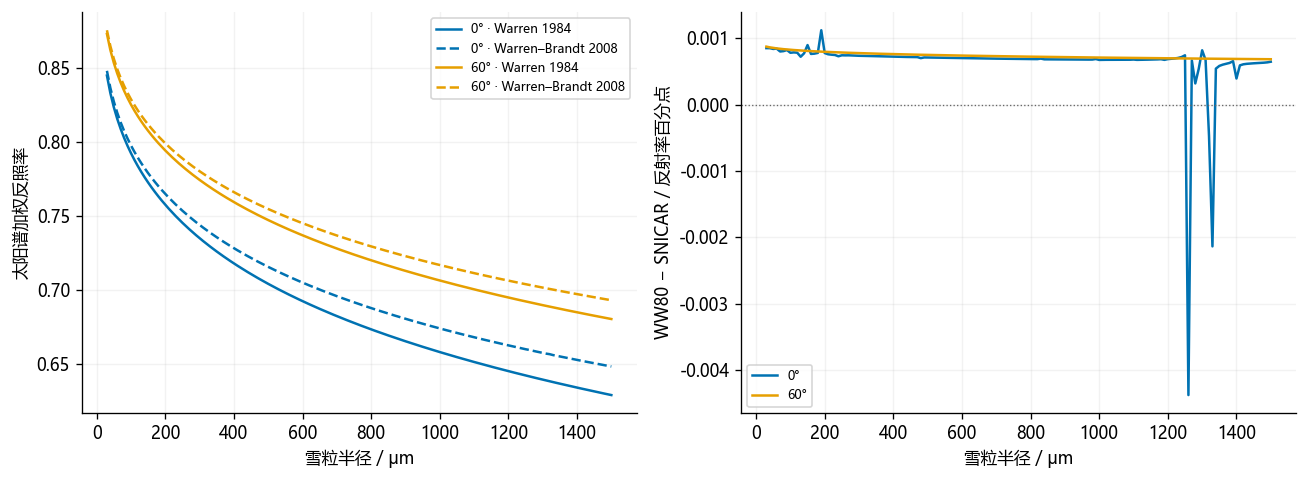

,radius_um,solar_zenith_deg,ice_option,snicar_albedo,ww80_albedo
2,50,0,1,0.82365,0.82365
7,100,0,1,0.79259,0.79260
17,200,0,1,0.75775,0.75776
47,500,0,1,0.70431,0.70432
97,1000,0,1,0.65825,0.65826
150,50,0,2,0.82746,0.82747
155,100,0,2,0.79778,0.79779
165,200,0,2,0.76505,0.76506
195,500,0,2,0.71577,0.71577
245,1000,0,2,0.67421,0.67421


In [4]:
figure = t.plot_broadband_albedo(forward)
display(figure)
plt.close(figure)
albedo = t.optics_table(forward)
display(albedo.query("radius_um in [50, 100, 200, 500, 1000] and solar_zenith_deg in [0, 60]").round(5))

## 4 再算一次加权平均

下面直接使用缓存中的太阳谱与光谱做点积，核对表中加权反照率。这个检查把数组、物理量和统计结果联系起来。

In [5]:
for ai, angle in enumerate(forward["angles_deg"]):
    flux = forward["solar_flux"][ai]
    reconstructed = np.sum(forward["ww_albedo"][:, :, ai, :] * flux[None, :, None], axis=1) / flux.sum()
    np.testing.assert_allclose(reconstructed, forward["broadband_ww"][:, ai, :], atol=1e-12)
print("WW80 太阳谱加权平均与冻结结果一致，绝对误差容限 1e-12。")

WW80 太阳谱加权平均与冻结结果一致，绝对误差容限 1e-12。


## 阅读结果

- 光谱曲线说明：粒径效应随波长变化，单个可见光反射率不足以表征雪粒径。
- 两个角度面板解释了为什么模拟几何需要固定。
- 两流近似与 adding-doubling 的差异保留在右图中，后续 Fig. 3 使用 WW80 分支。

下一步：[02 Fig. 3 与光谱混合分析](02_fig3_sma.ipynb)。来源与许可见仓库的数据说明及随附清单。